In [8]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
from glob import glob

In [115]:
! ls /gpfs/data/mock_lab/will/mosaic_tmp/binning_dir/3300055289/vacuum/

bins  bins_checked  semibin_cop.1.contigs.txt  vamb_bins  vamb_coords.tsv


In [12]:
sample_id = "3300055289"

df_umap_coords = pd.read_csv(
    f"/gpfs/data/mock_lab/will/mosaic_tmp/binning_dir/{sample_id}/vacuum/vamb_coords.tsv", 
    sep = '\t'
)
df_umap_coords['sample'] = df_umap_coords.contig_id.apply(lambda x: x.split('_')[0])
df_umap_coords.head()

,contig_id,umap_0,umap_1,sample
0,Ga0535628_0000001,0.948982,-4.160863,Ga0535628
1,Ga0535628_0000002,0.929222,-4.175056,Ga0535628
2,Ga0535628_0000003,1.068540,-4.083187,Ga0535628
3,Ga0535628_0000004,0.986165,-4.133917,Ga0535628
4,Ga0535628_0000005,15.494281,1.881091,Ga0535628


In [18]:
bins = pd.read_csv(
    f"/gpfs/data/mock_lab/will/mosaic_tmp/binning_dir/{sample_id}/vamb/vae_clusters.tsv", 
    sep = '\t', 
    names = ['vamb_bin_id', 'contig_id']
)
bins.head()


,vamb_bin_id,contig_id
0,vae_1,Ga0535628_0049950
1,vae_2,Ga0535628_0091646
2,vae_3,Ga0535628_0033821
3,vae_4,Ga0535628_0058028
4,vae_5,Ga0535628_0069027


In [19]:
vamb_bins = bins

vcounts = vamb_bins.groupby('vamb_bin_id').count()

vcounts = vcounts.to_dict()['contig_id']

In [23]:
df_mmseqs = pd.read_csv(
    f"/gpfs/data/mock_lab/will/mosaic_tmp/taxo_tmpdir/{sample_id}/{sample_id}.faa.mms2lca",
    sep = '\t'
)

In [24]:
df = pd.merge(
    df_umap_coords, 
    vamb_bins, 
    on = 'contig_id'
)

df['vamb_bin_id'] = df.vamb_bin_id.apply(lambda x: 'none' if vcounts[x] < 75 else x)

df = pd.merge(
    df, 
    df_mmseqs[['contig_id', 'name', 'superkingdom', 'lineage']], 
    on = 'contig_id', 
    how = 'left'
).fillna("None")



print(df.shape)
df.head()

(94889, 8)


,contig_id,umap_0,umap_1,sample,vamb_bin_id,name,superkingdom,lineage
0,Ga0535628_0000001,0.948982,-4.160863,Ga0535628,vae_3216,Gammaproteobacteria,Bacteria,Bacteria;Pseudomonadota;Gammaproteobacteria
1,Ga0535628_0000002,0.929222,-4.175056,Ga0535628,vae_3216,Pseudomonadaceae,Bacteria,Bacteria;Pseudomonadota;Gammaproteobacteria;Ps...
2,Ga0535628_0000003,1.068540,-4.083187,Ga0535628,vae_3216,Pseudomonadaceae,Bacteria,Bacteria;Pseudomonadota;Gammaproteobacteria;Ps...
3,Ga0535628_0000004,0.986165,-4.133917,Ga0535628,vae_3216,Pseudomonadaceae,Bacteria,Bacteria;Pseudomonadota;Gammaproteobacteria;Ps...
4,Ga0535628_0000005,15.494281,1.881091,Ga0535628,none,Rhodobiaceae bacterium,Bacteria,Bacteria;Pseudomonadota;Alphaproteobacteria;Hy...


In [30]:
df_copopod_bin = pd.read_csv(
    f"/gpfs/data/mock_lab/will/mosaic_tmp/binning_dir/{sample_id}/vacuum/semibin_cop.1.contigs.txt", 
    names = ['contig_id']
)

df['cpod_bin'] = df.contig_id.isin(df_copopod_bin.contig_id)

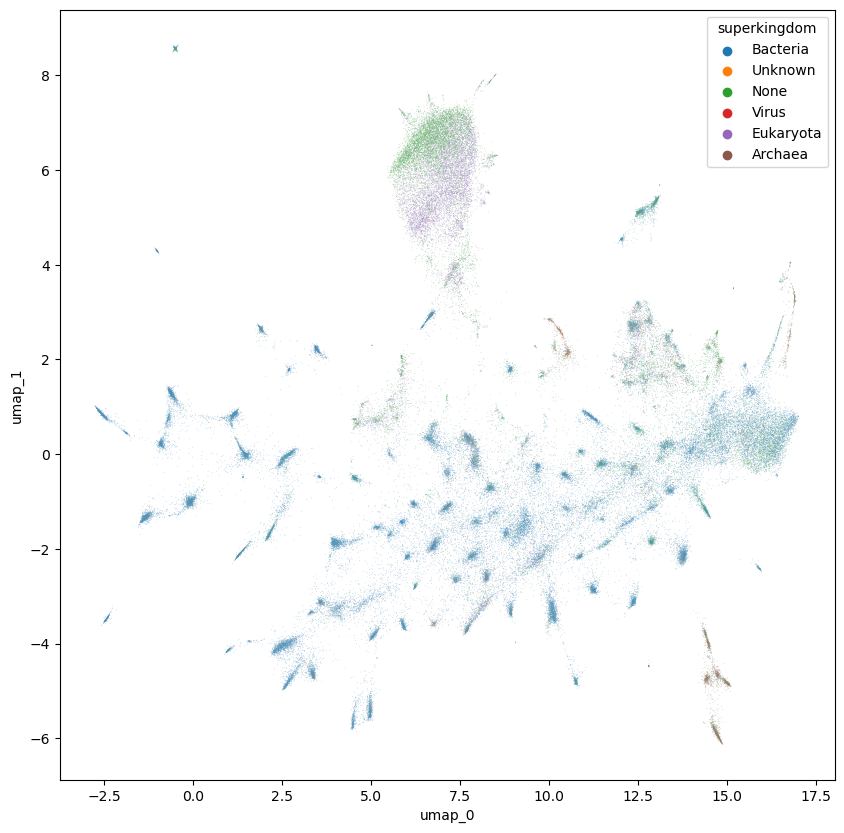

In [73]:
plt.figure(figsize = (10, 10))
ax = sns.scatterplot(
    data = df, 
    x = 'umap_0', 
    y = 'umap_1', 
    s = 0.25, 
    hue = 'superkingdom', 
    alpha = 0.5
)

In [ ]:
# Below here don't run - this is for processing of one bin!

In [74]:
from sklearn.decomposition import PCA

In [36]:
emb = np.load("/gpfs/data/mock_lab/will/mosaic_tmp/binning_dir/3300055289/vamb/latent.npz")["arr_0"]
emb.shape

In [71]:
cop_centre = emb[df[df.cpod_bin].index, :].mean(axis = 0)
df['emb_dist'] = ( np.linalg.norm((emb - cop_centre), axis = 1) < 15 )

In [ ]:
plt.figure(figsize = (10, 10))
ax = sns.scatterplot(
    data = df, 
    x = 'umap_0', 
    y = 'umap_1', 
    s = 0.25, 
    hue = 'emb_dist', 
    alpha = 0.5
)

In [75]:
pca = PCA(n_components = 32)

cop_pca = pca.fit(emb[df[df.cpod_bin].index, :])

In [90]:
emb2 = pca.transform(emb)

In [110]:
df['emb_dist'] = (df.cpod_bin) | (
    ( np.linalg.norm(emb2, ord = 1, axis = 1) < 75 ) & 
    (df.umap_1 > 3.2) & (df.umap_0 > 5) & (df.umap_0 < 9)
)

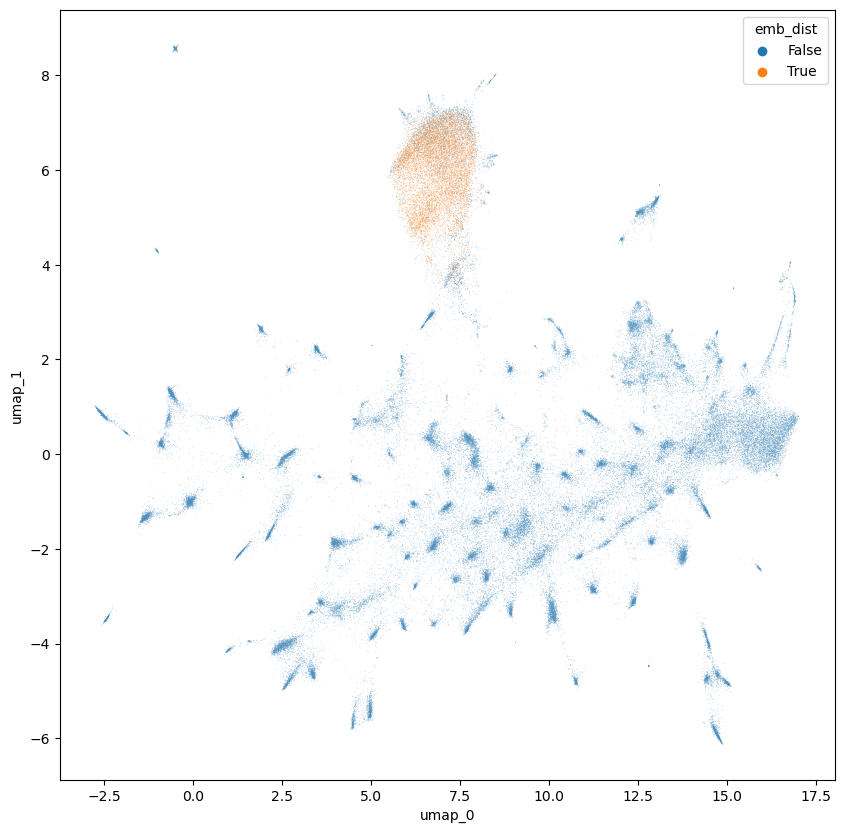

In [111]:
plt.figure(figsize = (10, 10))
ax = sns.scatterplot(
    data = df, 
    x = 'umap_0', 
    y = 'umap_1', 
    s = 0.25, 
    hue = 'emb_dist', 
    alpha = 0.5
)

In [116]:
df[df.emb_dist][['contig_id']].to_csv(
    f"/gpfs/data/mock_lab/will/mosaic_tmp/binning_dir/{sample_id}/vacuum/semibin_cop.1.v2.contigs.txt", index = False, header = None
)